# Routex: Notebook 05, Model Evaluation

**Project:** Routex, machine-learning-based vehicle fuel consumption prediction
**Author:** Member 2
**Target:** `comb08`, combined fuel economy (MPG)

This notebook evaluates the three models trained in
[`04_model_training.ipynb`](04_model_training.ipynb):

1. Linear Regression (fitted on `log(comb08)`, predictions converted back to MPG)
2. Decision Tree Regressor
3. Random Forest Regressor

### Rules followed

- The **saved, already-trained pipelines** in `models/` are loaded. **Nothing is
  trained or re-fitted on the test data.**
- All three models are scored on **exactly the same test set** (8,499 vehicles, the 20%
  split with `random_state = 42` from notebook 02).
- Every number in this notebook is **calculated from the models' actual predictions**.
  The predictions are also checked against those saved by notebook 04.
- Only the 22 approved, leakage-free features are used.

### Contents

1. Load the models and test data
2. Metrics: MAE, MSE, RMSE, R² (plus MAPE and maximum error)
3. How certain are the differences? (bootstrap confidence intervals)
4. Actual vs predicted plots
5. Residual analysis
6. Errors by vehicle group
7. Feature importance
8. Robustness check: grouped cross-validation (training data only)
9. Strengths and weaknesses
10. Conclusion

## 0. Setup

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (max_error, mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score, root_mean_squared_error)
from sklearn.model_selection import GroupKFold, cross_validate

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src import modeling as mdl
from src import preprocessing as prep

RANDOM_STATE = prep.RANDOM_STATE
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

BLUE, SERIES = "#257de0", ["#257de0", "#f47230", "#00b894"]
TEXT, TEXT_2, GRID = "#191919", "#666666", "#e6e6e6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight",
    "axes.edgecolor": GRID, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "axes.axisbelow": True, "xtick.color": TEXT_2,
    "ytick.color": TEXT_2, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"05_{name}.png")

print("scikit-learn", sklearn.__version__, "| random_state", RANDOM_STATE)

scikit-learn 1.9.1 | random_state 42


## 1. Load the trained models and the test data

The models are complete pipelines (preprocessing + model). If they are missing (e.g. on
a fresh clone, because `models/` is not in Git), run notebook 04 first. This notebook
deliberately does **not** retrain them.

In [2]:
MODEL_FILES = {
    "Linear Regression": "linear_regression",
    "Decision Tree": "decision_tree",
    "Random Forest": "random_forest",
}
models = {}
for name, stem in MODEL_FILES.items():
    path = mdl.MODELS_DIR / f"{stem}.joblib"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found - run notebooks/04_model_training.ipynb first.")
    models[name] = joblib.load(path)
    print(f"{name:<18} <- {path.relative_to(PROJECT_ROOT)}: {models[name].named_steps['model']}")

Linear Regression  <- models\linear_regression.joblib: TransformedTargetRegressor(func=<ufunc 'log'>, inverse_func=<ufunc 'exp'>,
                           regressor=LinearRegression())
Decision Tree      <- models\decision_tree.joblib: DecisionTreeRegressor(max_depth=24, random_state=42)


Random Forest      <- models\random_forest.joblib: RandomForestRegressor(max_features=0.6, n_estimators=300, n_jobs=-1,
                      random_state=42)


In [3]:
raw = prep.load_raw_data()
clean, _ = prep.clean_dataset(raw)
X_train, X_test, y_train, y_test = prep.split_features_target(clean)
print(f"Test set: {len(X_test):,} vehicles (identical for all three models)")
print(f"Training set: {len(X_train):,} vehicles (used only for train scores and the Section 8 check)")

# Predictions of the saved models on the test set
test_pred = {name: m.predict(X_test) for name, m in models.items()}
train_pred = {name: m.predict(X_train) for name, m in models.items()}

# Consistency check against the predictions saved by notebook 04
saved = pd.read_csv(mdl.RESULTS_DIR / "test_predictions.csv")
assert np.allclose(saved["actual_comb08"], y_test.values)
for name, stem in MODEL_FILES.items():
    assert np.allclose(saved[f"pred_{stem}"], test_pred[name], atol=1e-3), name
print("Predictions match results/test_predictions.csv from notebook 04.")

Test set: 8,499 vehicles (identical for all three models)
Training set: 33,994 vehicles (used only for train scores and the Section 8 check)


Predictions match results/test_predictions.csv from notebook 04.


## 2. Model comparison table

| Metric | Formula (in words) | Unit | Better |
|---|---|---|---|
| **MAE** | average of \|actual − predicted\| | MPG | lower |
| **MSE** | average of (actual − predicted)² | MPG² | lower |
| **RMSE** | √MSE; like MAE but punishes large errors more | MPG | lower |
| **R²** | 1 − (model's squared error / squared error of always predicting the mean) | none | higher (max 1) |
| MAPE | average of \|error\| / actual | % | lower |
| Max error | the single worst prediction | MPG | lower |

In [4]:
def all_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAPE_%": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "Max_error": max_error(y_true, y_pred),
    }

test_metrics = pd.DataFrame({n: all_metrics(y_test, p) for n, p in test_pred.items()}).T
baseline_pred = np.full(len(y_test), y_train.mean())          # mean of the TRAINING target
test_metrics.loc["Baseline (training mean)"] = all_metrics(y_test, baseline_pred)
test_metrics["Rank (RMSE)"] = test_metrics["RMSE"].rank().astype(int)
test_metrics.round(4)

,MAE,MSE,RMSE,R2,MAPE_%,Max_error,Rank (RMSE)
Linear Regression,1.2831,3.3245,1.8233,0.8849,6.3041,18.9280,3
Decision Tree,0.4731,0.8819,0.9391,0.9695,2.4191,15.0000,2
Random Forest,0.4764,0.5659,0.7523,0.9804,2.4572,7.5381,1
Baseline (training mean),4.0300,28.9028,5.3761,-0.0007,21.2412,37.6150,4


In [5]:
train_metrics = pd.DataFrame({n: all_metrics(y_train, p) for n, p in train_pred.items()}).T
fit_gap = pd.DataFrame({
    "train_RMSE": train_metrics["RMSE"], "test_RMSE": test_metrics.loc[list(models), "RMSE"],
    "train_R2": train_metrics["R2"], "test_R2": test_metrics.loc[list(models), "R2"],
})
fit_gap["RMSE_ratio_test/train"] = fit_gap["test_RMSE"] / fit_gap["train_RMSE"]
print("Training vs test performance (overfitting check):")
fit_gap.round(3)

Training vs test performance (overfitting check):


,train_RMSE,test_RMSE,train_R2,test_R2,RMSE_ratio_test/train
Linear Regression,1.807,1.823,0.885,0.885,1.009
Decision Tree,0.370,0.939,0.995,0.969,2.540
Random Forest,0.361,0.752,0.995,0.980,2.081


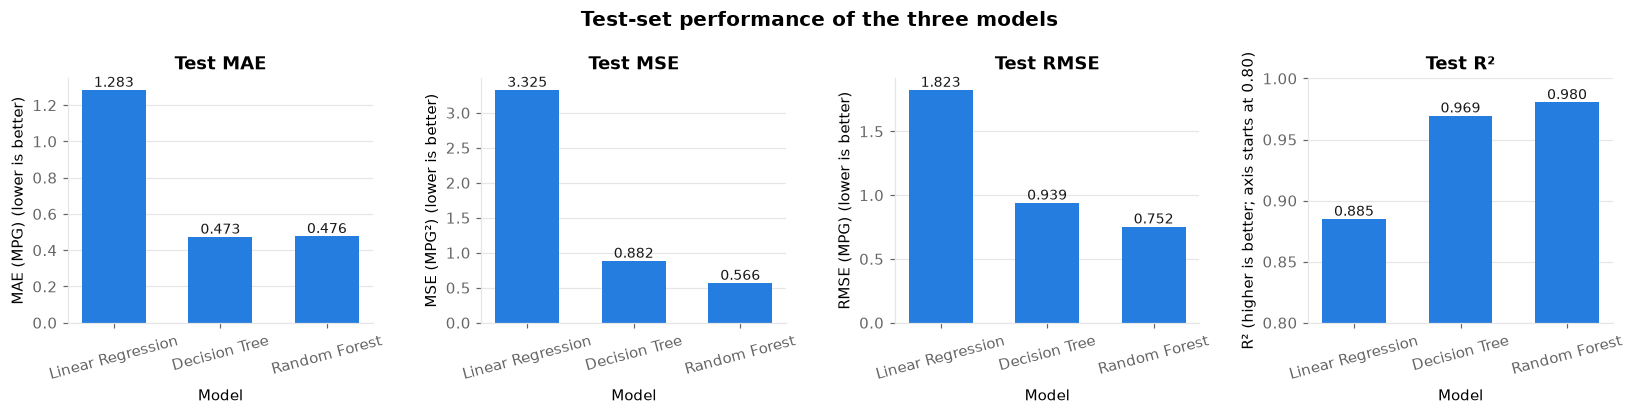

In [6]:
names = list(models)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, metric, label in zip(axes, ["MAE", "MSE", "RMSE", "R2"],
                             ["MAE (MPG)", "MSE (MPG²)", "RMSE (MPG)", "R²"]):
    vals = test_metrics.loc[names, metric]
    bars = ax.bar(names, vals, color=BLUE, width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom",
                fontsize=9, color=TEXT)
    ax.set_title(f"Test {metric if metric != 'R2' else 'R²'}")
    ax.set_ylabel(label + (" (higher is better; axis starts at 0.80)" if metric == "R2"
                           else " (lower is better)"))
    ax.set_xlabel("Model")
    ax.tick_params(axis="x", labelrotation=15)
    ax.grid(axis="x", visible=False)
    if metric == "R2":
        ax.set_ylim(min(0.8, vals.min() - 0.02), 1.0)
fig.suptitle("Test-set performance of the three models", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "metric_comparison")
plt.show()

## 3. How certain are the differences? Bootstrap confidence intervals

The test set is one sample of vehicles. A different sample would give slightly
different scores. **Bootstrapping** estimates this uncertainty: we draw 1,000 random
resamples of the test set (with replacement, fixed seed) and recompute the metrics on
each. The same resample is used for all three models, so the **differences** between
models can be compared directly. No model is refitted; only the existing predictions are
re-scored.

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
N_BOOT = 1000
y_arr = y_test.to_numpy(dtype=float)
boot = {n: {"RMSE": [], "MAE": [], "R2": []} for n in names}
diff_rf_dt, diff_rf_lr = [], []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    yt = y_arr[idx]
    rmse_b = {}
    for n in names:
        yp = test_pred[n][idx]
        rmse_b[n] = root_mean_squared_error(yt, yp)
        boot[n]["RMSE"].append(rmse_b[n])
        boot[n]["MAE"].append(mean_absolute_error(yt, yp))
        boot[n]["R2"].append(r2_score(yt, yp))
    diff_rf_dt.append(rmse_b["Decision Tree"] - rmse_b["Random Forest"])
    diff_rf_lr.append(rmse_b["Linear Regression"] - rmse_b["Random Forest"])

ci_rows = []
for n in names:
    row = {"model": n}
    for m in ["RMSE", "MAE", "R2"]:
        lo, hi = np.percentile(boot[n][m], [2.5, 97.5])
        row[f"{m}"] = test_metrics.loc[n, m]
        row[f"{m}_95%_CI"] = f"[{lo:.3f}, {hi:.3f}]"
    ci_rows.append(row)
ci_table = pd.DataFrame(ci_rows).set_index("model")
display(ci_table.round(4))

for label, d in [("Decision Tree − Random Forest", diff_rf_dt),
                 ("Linear Regression − Random Forest", diff_rf_lr)]:
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"RMSE difference {label}: {np.mean(d):.3f} MPG, 95% CI [{lo:.3f}, {hi:.3f}], "
          f"Random Forest better in {np.mean(np.array(d) > 0):.1%} of resamples")

,RMSE,RMSE_95%_CI,MAE,MAE_95%_CI,R2,R2_95%_CI
model,,,,,,
Linear Regression,1.8233,"[1.759, 1.884]",1.2831,"[1.255, 1.310]",0.8849,"[0.878, 0.891]"
Decision Tree,0.9391,"[0.896, 0.986]",0.4731,"[0.457, 0.491]",0.9695,"[0.966, 0.972]"
Random Forest,0.7523,"[0.729, 0.776]",0.4764,"[0.464, 0.488]",0.9804,"[0.979, 0.982]"


RMSE difference Decision Tree − Random Forest: 0.187 MPG, 95% CI [0.155, 0.224], Random Forest better in 100.0% of resamples
RMSE difference Linear Regression − Random Forest: 1.070 MPG, 95% CI [1.006, 1.128], Random Forest better in 100.0% of resamples


## 4. Actual vs predicted

Each point is one test vehicle. Points on the dashed line are perfect predictions.
Colour shows **how many vehicles** fall in each area (darker = more), because thousands
of points overlap.

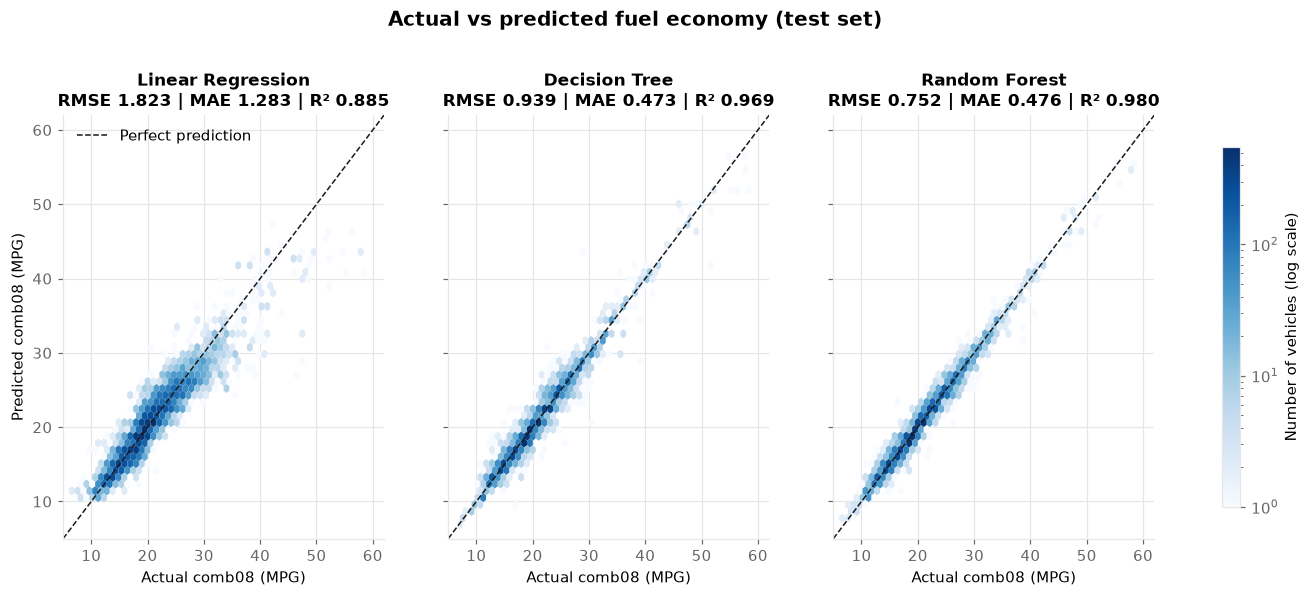

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lims = (5, 62)
for ax, n in zip(axes, names):
    hb = ax.hexbin(y_test, test_pred[n], gridsize=55, extent=(*lims, *lims), bins="log",
                   cmap="Blues", mincnt=1, linewidths=0)
    ax.plot(lims, lims, color=TEXT, linestyle="--", linewidth=1, label="Perfect prediction")
    m = test_metrics.loc[n]
    ax.set_title(f"{n}\nRMSE {m.RMSE:.3f} | MAE {m.MAE:.3f} | R² {m.R2:.3f}", fontsize=11)
    ax.set_xlabel("Actual comb08 (MPG)")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
axes[0].set_ylabel("Predicted comb08 (MPG)")
axes[0].legend(loc="upper left")
fig.colorbar(hb, ax=axes, label="Number of vehicles (log scale)", shrink=0.85)
fig.suptitle("Actual vs predicted fuel economy (test set)", fontsize=13, fontweight="bold", x=0.45, y=1.07)
save(fig, "actual_vs_predicted")
plt.show()

**Observations:**

- **Random Forest** points form the tightest band around the diagonal across the whole
  range, including the hybrids at 40 to 58 MPG.
- **Decision Tree** is also tight, but it produces a limited set of distinct values (one
  per leaf), and a few vehicles are far off the line.
- **Linear Regression** is accurate for typical cars (15 to 30 MPG), but **flattens out
  for high-MPG vehicles**: cars above 40 MPG are predicted at only about 35 to 45 MPG.
  A linear model cannot represent the large extra gain that hybrid technology gives a
  small engine.

## 5. Residual analysis

A **residual** is `actual − predicted`:

- residual > 0: the model **under-predicted** (the car is more efficient than predicted),
- residual < 0: the model **over-predicted**.

A good model has residuals centred on 0, with no pattern against the predicted value.

In [9]:
residuals = {n: y_test.to_numpy() - test_pred[n] for n in names}
res_stats = pd.DataFrame({
    n: {"mean (bias)": r.mean(), "median": np.median(r), "std": r.std(),
        "share |res| <= 0.5 MPG": np.mean(np.abs(r) <= 0.5),
        "share |res| <= 1 MPG": np.mean(np.abs(r) <= 1),
        "share |res| <= 2 MPG": np.mean(np.abs(r) <= 2),
        "share |res| > 5 MPG": np.mean(np.abs(r) > 5)}
    for n, r in residuals.items()}).T
res_stats.round(3)

,mean (bias),median,std,share |res| <= 0.5 MPG,share |res| <= 1 MPG,share |res| <= 2 MPG,share |res| > 5 MPG
Linear Regression,0.031,0.007,1.823,0.280,0.513,0.811,0.017
Decision Tree,-0.014,0.000,0.939,0.674,0.897,0.970,0.002
Random Forest,-0.031,-0.007,0.752,0.656,0.880,0.974,0.001


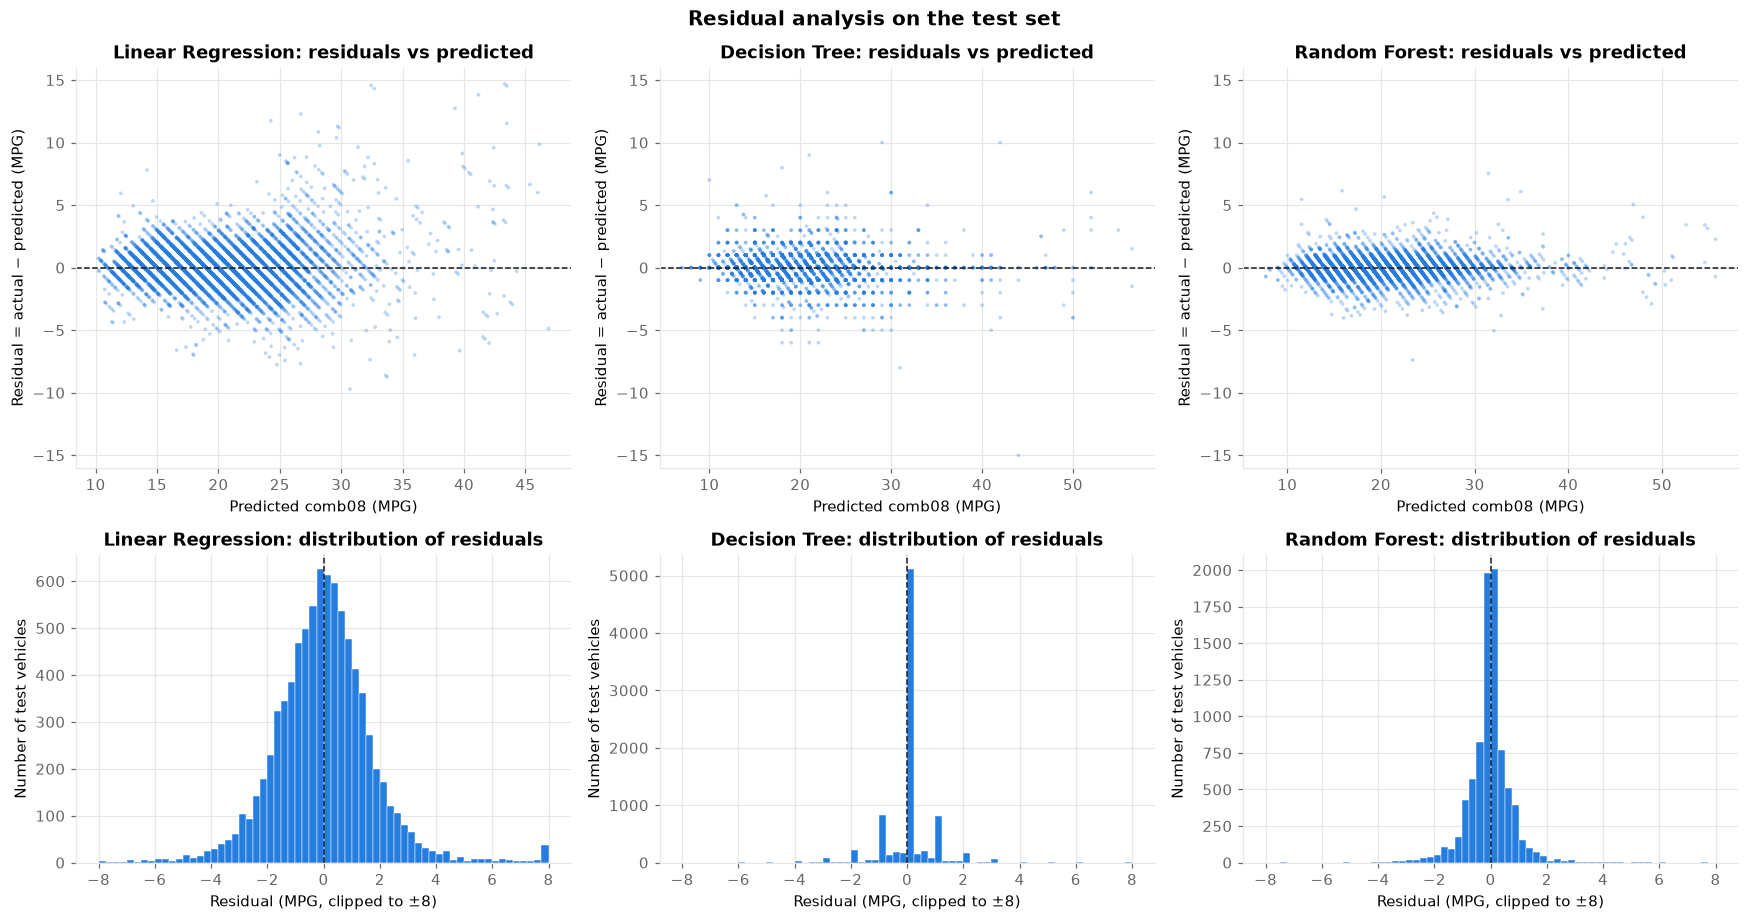

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), gridspec_kw={"height_ratios": [1.3, 1]})
for i, n in enumerate(names):
    ax = axes[0, i]
    ax.scatter(test_pred[n], residuals[n], s=6, alpha=0.3, color=BLUE, edgecolors="none")
    ax.axhline(0, color=TEXT, linewidth=1, linestyle="--")
    ax.set_title(f"{n}: residuals vs predicted")
    ax.set_xlabel("Predicted comb08 (MPG)")
    ax.set_ylabel("Residual = actual − predicted (MPG)")
    ax.set_ylim(-16, 16)

    ax = axes[1, i]
    ax.hist(np.clip(residuals[n], -8, 8), bins=np.arange(-8, 8.25, 0.25), color=BLUE,
            edgecolor="white", linewidth=0.3)
    ax.axvline(0, color=TEXT, linewidth=1, linestyle="--")
    ax.set_title(f"{n}: distribution of residuals")
    ax.set_xlabel("Residual (MPG, clipped to ±8)")
    ax.set_ylabel("Number of test vehicles")
fig.suptitle("Residual analysis on the test set", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "residuals")
plt.show()

In [11]:
# Does the error depend on how efficient the vehicle is? Mean residual per actual-MPG band.
bands = pd.cut(y_test, [0, 15, 20, 25, 30, 40, 60], labels=["<=15", "15-20", "20-25", "25-30", "30-40", ">40"])
by_band = pd.DataFrame({n: pd.Series(residuals[n], index=y_test.index).groupby(bands, observed=True).mean()
                        for n in names})
by_band.insert(0, "vehicles", bands.value_counts().reindex(by_band.index))
print("Mean residual (bias) by actual-MPG band. Positive = under-prediction:")
by_band.round(2)

Mean residual (bias) by actual-MPG band. Positive = under-prediction:


,vehicles,Linear Regression,Decision Tree,Random Forest
comb08,,,,
<=15,1550,-0.44,-0.14,-0.19
15-20,3326,-0.19,-0.05,-0.06
20-25,2444,-0.14,0.01,0.00
25-30,850,1.00,0.20,0.18
30-40,276,2.63,0.11,0.21
>40,53,6.66,0.49,0.55


**Observations:**

- All three models are **unbiased overall**: the mean residual is within ±0.03 MPG of 0.
- **Linear Regression has a systematic pattern.** It over-predicts the least efficient
  vehicles (bias −0.44 MPG at ≤15 MPG) and strongly **under-predicts the most efficient
  ones** (+2.6 MPG at 30 to 40 MPG, +6.7 MPG above 40 MPG). Its residuals also spread
  out more as predictions increase. This is the curved relationship found in the EDA
  that a linear model cannot capture. The diagonal stripes in its scatter plot come from
  the target being whole numbers.
- **Decision Tree** residuals are sharply concentrated at exactly 0 (67% within
  ±0.5 MPG), because its leaves often reproduce the MPG of near-identical training
  vehicles. However, it has more **large mistakes** than the forest (worst error
  15 MPG).
- **Random Forest** residuals are narrow and symmetric with no visible pattern. Its bias
  stays below 0.6 MPG in every MPG band, only 0.1% of vehicles are off by more than
  5 MPG, and its worst error (7.5 MPG) is half that of the single tree.

## 6. Errors by vehicle group

Overall scores are dominated by the 91% conventional petrol vehicles. As the EDA
recommended, we check the error separately for each powertrain type, and for the
largest vehicle classes, so poor performance on a small group is not hidden.

In [12]:
eval_df = X_test[["atvType", "VClass", "year"]].copy()
eval_df["actual"] = y_test.values
for n in names:
    eval_df[f"abs_err_{n}"] = np.abs(residuals[n])
    eval_df[f"sq_err_{n}"] = residuals[n] ** 2

def group_errors(col, min_count=1):
    g = eval_df.groupby(col)
    out = pd.DataFrame({"vehicles": g.size(), "mean_actual_MPG": g["actual"].mean()})
    for n in names:
        out[f"RMSE {n}"] = np.sqrt(g[f"sq_err_{n}"].mean())
    for n in names:
        out[f"MAE {n}"] = g[f"abs_err_{n}"].mean()
    return out[out["vehicles"] >= min_count].sort_values("vehicles", ascending=False)

by_powertrain = group_errors("atvType")
by_powertrain.round(3)

,vehicles,mean_actual_MPG,RMSE Linear Regression,RMSE Decision Tree,RMSE Random Forest,MAE Linear Regression,MAE Decision Tree,MAE Random Forest
atvType,,,,,,,,
Conventional,7792,19.938,1.711,0.900,0.727,1.237,0.467,0.468
FFV,265,17.687,1.148,0.772,0.546,0.873,0.344,0.322
Diesel,224,23.786,2.358,1.194,1.009,1.689,0.613,0.600
Hybrid,160,31.700,4.456,2.033,1.344,3.198,0.862,0.843
Plug-in Hybrid,43,31.116,3.761,0.964,1.371,2.841,0.372,0.904
CNG,9,19.333,2.549,0.000,0.874,1.955,0.000,0.645
Bifuel (CNG),6,13.833,0.862,0.707,0.811,0.672,0.500,0.649


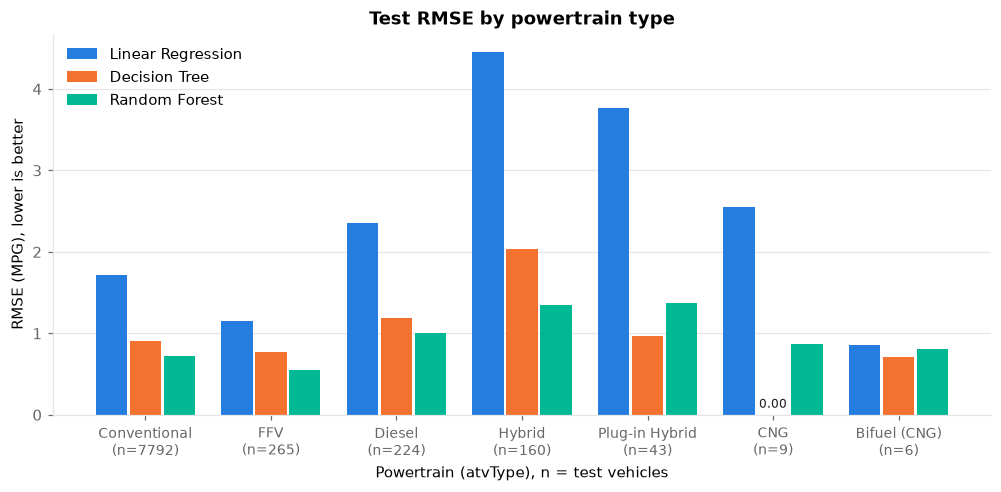

In [13]:
order = by_powertrain.index.tolist()
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(order))
for i, n in enumerate(names):
    vals = by_powertrain.loc[order, f"RMSE {n}"]
    ax.bar(x + (i - 1) * 0.27, vals, width=0.25, color=SERIES[i], label=n)
    for xi, v in zip(x, vals):
        if v < 0.05:   # a zero-height bar would look like missing data
            ax.text(xi + (i - 1) * 0.27, 0.05, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color=TEXT)
ax.set_xticks(x, [f"{o}\n(n={by_powertrain.loc[o, 'vehicles']})" for o in order], fontsize=9)
ax.set_title("Test RMSE by powertrain type")
ax.set_xlabel("Powertrain (atvType), n = test vehicles")
ax.set_ylabel("RMSE (MPG), lower is better")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
save(fig, "rmse_by_powertrain")
plt.show()

In [14]:
by_class = group_errors("VClass", min_count=150)
by_class.round(3)

,vehicles,mean_actual_MPG,RMSE Linear Regression,RMSE Decision Tree,RMSE Random Forest,MAE Linear Regression,MAE Decision Tree,MAE Random Forest
VClass,,,,,,,,
Compact Cars,1225,23.778,1.878,1.010,0.778,1.448,0.484,0.498
Midsize Cars,1026,22.090,1.868,0.988,0.728,1.378,0.452,0.460
Subcompact Cars,1020,22.552,2.348,0.904,0.685,1.599,0.433,0.451
Standard Pickup Trucks,480,15.108,1.035,0.787,0.650,0.810,0.479,0.442
Large Cars,468,20.017,2.079,0.910,0.658,1.275,0.406,0.394
Sport Utility Vehicle - 4WD,417,17.400,1.388,0.873,0.736,1.067,0.499,0.504
Two Seaters,407,19.570,2.772,0.961,0.848,1.829,0.399,0.474
Minicompact Cars,299,20.769,2.067,0.739,0.653,1.330,0.371,0.413
Special Purpose Vehicles,297,16.717,1.710,0.933,0.780,1.242,0.459,0.471


**Observations:**

- **Hybrids are the hardest group for every model** (160 test vehicles). Random Forest
  handles them best (RMSE 1.34), the Decision Tree is worse (2.03), and Linear Regression
  is poor (4.46, about 3 times its error on conventional cars).
- For **plug-in hybrids** (only 43 test vehicles) the Decision Tree happens to score
  best (RMSE 0.96 vs 1.37 for the forest). With so few vehicles this difference is not
  reliable, but it shows the forest is not best in *every* group.
- **Diesels** are also harder than conventional petrol (forest RMSE 1.01 vs 0.73).
- Across the **15 largest vehicle classes**, Random Forest has the lowest RMSE in every
  class (0.59 to 0.99 MPG). Linear Regression is weakest for two-seaters (2.77) and
  subcompacts (2.35), the classes that contain the most efficient and the most unusual
  cars.
- The CNG and bi-fuel groups have fewer than 10 test vehicles each, so their scores
  are not meaningful. (The Decision Tree's RMSE of 0.00 for CNG means it predicted all
  9 CNG test vehicles exactly. This is a small-sample effect, not a sign of a better model.)

## 7. Feature importance

Two complementary methods are used:

1. **Impurity-based importance** (Decision Tree and Random Forest only). This is built
   into tree models: how much each feature reduced the squared error across all the
   splits that used it. It is computed from the **training** data during fitting, and it
   tends to favour features with many distinct values.
2. **Permutation importance** (all three models, including Linear Regression). Shuffle
   one feature in the **test set** and measure how much the RMSE gets worse. A large
   increase means the model relies on that feature. It is computed on unseen data, works
   the same way for every model, and **does not retrain anything**.

Linear Regression has no built-in importance. Its coefficients cannot be read as
importance here: they are on the log scale, the one-hot columns are redundant, and
`displ`/`cylinders` are strongly correlated (EDA). Permutation importance is the fair
way to compare it.

One-hot columns are added back up to their original feature (e.g. all `make_*` columns
count as `make`), so all three models are compared on the same 22 features.

In [15]:
def original_feature(name):
    # Map a transformed column name (e.g. 'cat__make_Toyota') back to its raw feature.
    block, rest = name.split("__", 1)
    if block == "num":
        return rest.replace("missingindicator_", "")
    if block == "bin":
        return rest
    matches = [f for f in prep.CATEGORICAL_FEATURES if rest.startswith(f + "_")]
    return max(matches, key=len)

impurity = {}
for n in ["Decision Tree", "Random Forest"]:
    pipe = models[n]
    cols = pipe.named_steps["preprocess"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=cols)
    impurity[n] = imp.groupby(imp.index.map(original_feature)).sum()
impurity = pd.DataFrame(impurity).reindex(prep.FEATURES).fillna(0)
impurity = impurity.sort_values("Random Forest", ascending=False)
impurity.round(4).head(12)

,Decision Tree,Random Forest
displ,0.6425,0.4620
cylinders,0.0084,0.1361
atvType,0.0800,0.0753
drive,0.0300,0.0584
year,0.0687,0.0561
startStop,0.0066,0.0306
make,0.0279,0.0277
passenger_volume,0.0170,0.0265
luggage_volume,0.0208,0.0246
fuelType,0.0321,0.0160


In [16]:
start = time.perf_counter()
perm = {}
for n in names:
    r = permutation_importance(models[n], X_test, y_test, scoring="neg_root_mean_squared_error",
                               n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
    perm[n] = pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std}, index=X_test.columns)
print(f"Permutation importance computed in {time.perf_counter() - start:.0f} s "
      f"(22 features x 5 repeats x 3 models)")

perm_mean = pd.DataFrame({n: perm[n]["mean"] for n in names})
perm_mean = perm_mean.sort_values("Random Forest", ascending=False)
print("Increase in test RMSE (MPG) when each feature is shuffled:")
perm_mean.round(3)

Permutation importance computed in 27 s (22 features x 5 repeats x 3 models)
Increase in test RMSE (MPG) when each feature is shuffled:


,Linear Regression,Decision Tree,Random Forest
displ,2.226,5.022,3.573
atvType,0.403,2.000,1.190
year,0.438,1.798,1.159
cylinders,0.234,0.535,0.897
drive,0.356,1.144,0.873
luggage_volume,0.790,0.908,0.407
passenger_volume,0.670,0.636,0.390
startStop,0.061,0.314,0.368
make,0.513,0.585,0.348
turbo,0.115,0.440,0.272


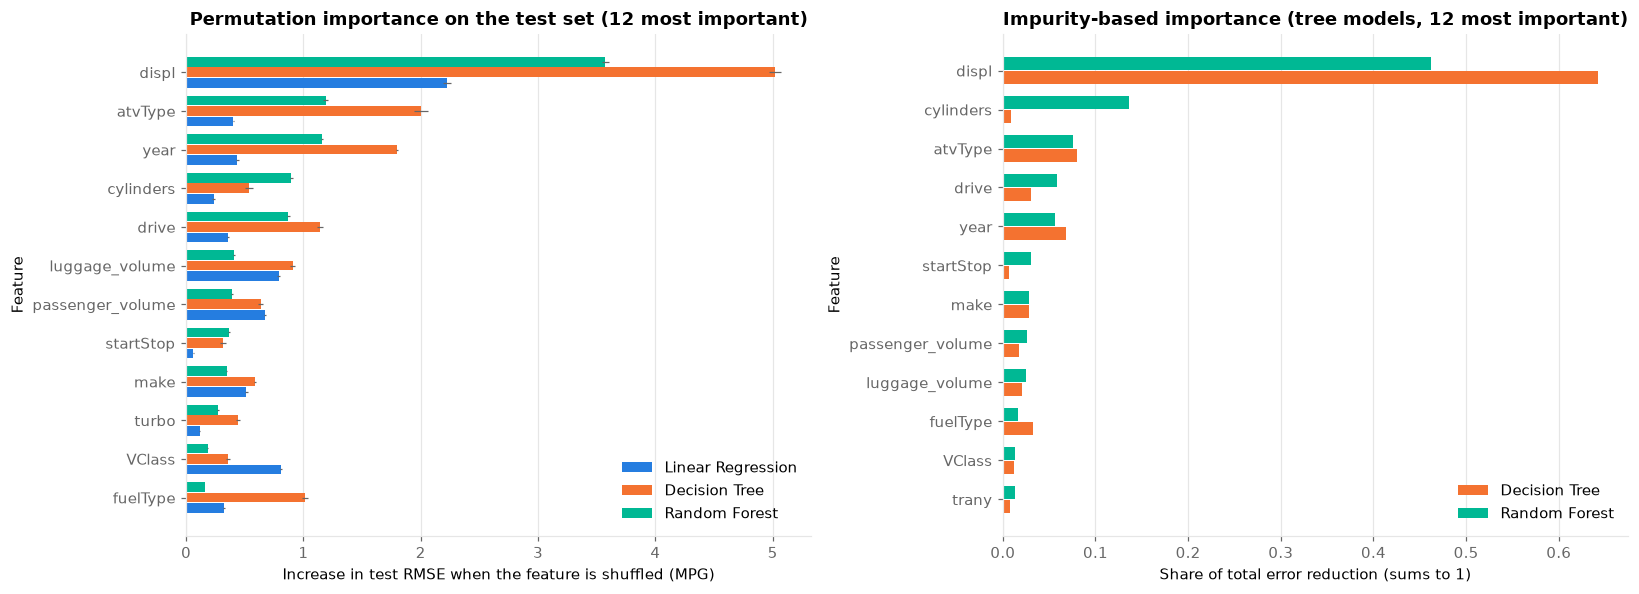

In [17]:
top = perm_mean.head(12).index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
y = np.arange(len(top))
for i, n in enumerate(names):
    axes[0].barh(y + (i - 1) * 0.27, perm_mean.loc[top, n], height=0.25, color=SERIES[i],
                 xerr=perm[n].loc[top, "std"], error_kw={"elinewidth": 0.8, "ecolor": TEXT_2},
                 label=n)
axes[0].set_yticks(y, top)
axes[0].set_title("Permutation importance on the test set (12 most important)")
axes[0].set_xlabel("Increase in test RMSE when the feature is shuffled (MPG)")
axes[0].set_ylabel("Feature")
axes[0].legend(loc="lower right")
axes[0].grid(axis="y", visible=False)

top_imp = impurity.head(12).index[::-1]
y2 = np.arange(len(top_imp))
for i, n in enumerate(["Decision Tree", "Random Forest"]):
    axes[1].barh(y2 + (i - 0.5) * 0.36, impurity.loc[top_imp, n], height=0.34,
                 color=SERIES[i + 1], label=n)
axes[1].set_yticks(y2, top_imp)
axes[1].set_title("Impurity-based importance (tree models, 12 most important)")
axes[1].set_xlabel("Share of total error reduction (sums to 1)")
axes[1].set_ylabel("Feature")
axes[1].legend(loc="lower right")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "feature_importance")
plt.show()

**Observations:**

- **Engine displacement (`displ`) is by far the most important feature for all three
  models.** Shuffling it increases the forest's test RMSE by 3.6 MPG (Decision Tree
  5.0, Linear Regression 2.2). This confirms the EDA finding.
- **Powertrain type (`atvType`) and model year** come next for the tree models. Both
  matter a lot (they capture hybrid technology and the post-2008 efficiency trend),
  followed by `cylinders` and `drive`.
- **The single tree concentrates on very few features** (64% of its impurity importance
  is `displ`, while `cylinders` gets less than 1%). The forest **shares the importance
  between correlated features** (`displ` 46%, `cylinders` 14%), because each tree only
  sees part of the features at each split. This makes the forest less dependent on any
  single input.
- **Linear Regression relies more on vehicle class and interior volumes** (`VClass`,
  `luggage_volume`, `passenger_volume`). Without the ability to model interactions, it
  uses these as proxies for vehicle size and weight.
- Features such as `phevBlended`, `fuelType2` and `supercharger` add almost nothing on
  their own. They describe very few vehicles, or information that other features
  already cover.
- *Caveat:* when two features are strongly correlated (`displ`/`cylinders`,
  `year`/`trans_speeds`), shuffling one still leaves the other available, so permutation
  importance can understate both. The two methods agree on the overall ranking.

## 8. Robustness check: are the scores optimistic?

The same vehicle model (e.g. a Toyota Corolla) appears in many model years with nearly
identical specifications. With a **random** split, near-copies of a test vehicle are
usually in the training set, and a deep tree can almost look up the answer. That is
realistic if Routex is used for vehicles *similar to known models*, but optimistic for
**genuinely new models**.

**Check:** 5-fold cross-validation **on the training set only**, using **GroupKFold**:
all records of the same `make + model` stay in the same fold, so the validation fold
contains only vehicle models the pipeline has never seen. The selected hyperparameters
from notebook 04 are reused (fresh copies of the pipelines are fitted inside each fold).
**The test set is not used, and the saved final models are not changed.** We compare
with the random 5-fold CV scores from notebook 04.

In [18]:
# Recover the 'model' name for each cleaned row: clean_dataset keeps the order of the
# raw rows after removing EVs and duplicates, so the same filter re-aligns them.
kept = raw.loc[~prep.is_pure_electric(raw)]
kept = kept.loc[~kept.drop(columns=[prep.ID_COLUMN]).duplicated(keep="first")].reset_index(drop=True)
assert (kept["make"].values == clean["make"].values).all() and len(kept) == len(clean)
groups_train = (kept["make"] + " | " + kept["model"]).loc[X_train.index]
print(f"Training rows: {len(X_train):,} | distinct make+model groups: {groups_train.nunique():,}")

random_cv = pd.read_csv(mdl.RESULTS_DIR / "model_metrics.csv", index_col="model")
rows = []
start = time.perf_counter()
for n in names:
    res = cross_validate(clone(models[n]), X_train, y_train, groups=groups_train,
                         cv=GroupKFold(n_splits=5), scoring=mdl.CV_SCORING, n_jobs=1)
    s = mdl.cv_summary(res, None)
    rows.append({"model": n,
                 "random_CV_RMSE (nb 04)": random_cv.loc[n, "cv_rmse"],
                 "grouped_CV_RMSE": s["cv_rmse"], "grouped_CV_RMSE_std": s["cv_rmse_std"],
                 "random_CV_R2 (nb 04)": random_cv.loc[n, "cv_r2"],
                 "grouped_CV_R2": s["cv_r2"], "grouped_CV_MAE": s["cv_mae"]})
grouped = pd.DataFrame(rows).set_index("model")
grouped["RMSE increase"] = grouped["grouped_CV_RMSE"] - grouped["random_CV_RMSE (nb 04)"]
print(f"Grouped CV finished in {time.perf_counter() - start:.0f} s")
grouped.round(3)

Training rows: 33,994 | distinct make+model groups: 4,068


Grouped CV finished in 53 s


,random_CV_RMSE (nb 04),grouped_CV_RMSE,grouped_CV_RMSE_std,random_CV_R2 (nb 04),grouped_CV_R2,grouped_CV_MAE,RMSE increase
model,,,,,,,
Linear Regression,1.831,1.903,0.048,0.882,0.872,1.334,0.072
Decision Tree,1.048,1.719,0.083,0.961,0.895,0.968,0.671
Random Forest,0.814,1.296,0.070,0.977,0.940,0.813,0.482


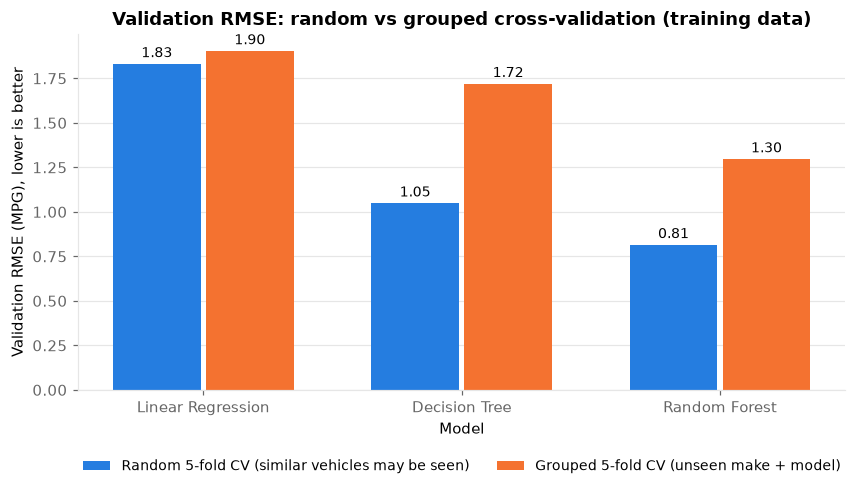

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(names))
for i, (col, label) in enumerate([("random_CV_RMSE (nb 04)", "Random 5-fold CV (similar vehicles may be seen)"),
                                  ("grouped_CV_RMSE", "Grouped 5-fold CV (unseen make + model)")]):
    vals = grouped.loc[names, col]
    bars = ax.bar(x + (i - 0.5) * 0.36, vals, width=0.34, color=SERIES[i], label=label)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, names)
ax.set_title("Validation RMSE: random vs grouped cross-validation (training data)")
ax.set_xlabel("Model")
ax.set_ylabel("Validation RMSE (MPG), lower is better")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=9)
ax.grid(axis="x", visible=False)
save(fig, "grouped_cv_check")
plt.show()

**Observations:**

- When the validation folds contain **only vehicle models never seen in training**, all
  errors increase, but by very different amounts:
  - Linear Regression: +0.07 MPG (1.83 → 1.90). It learned general trends, not
    individual vehicles.
  - **Decision Tree: +0.67 MPG (1.05 → 1.72)**, the largest drop. Much of its random-split
    accuracy came from recognising near-identical training vehicles.
  - Random Forest: +0.48 MPG (0.81 → 1.30, R² 0.94).
- **Random Forest is still the best model** in this harder setting, and the Decision
  Tree is now only slightly better than Linear Regression (1.72 vs 1.90).
- **Interpretation:** the random-split test scores in Section 2 are realistic for
  vehicles similar to models already in the dataset (the main use case: new model years
  and variants). For a **completely new vehicle model**, expect a typical error of about
  1.3 MPG RMSE (about 0.8 MPG MAE) from the Random Forest rather than 0.75.

## 9. Save the evaluation results

In [20]:
out = mdl.RESULTS_DIR
test_metrics.to_csv(out / "evaluation_test_metrics.csv", float_format="%.5f", index_label="model")
ci_table.to_csv(out / "evaluation_bootstrap_ci.csv", float_format="%.5f")
fit_gap.to_csv(out / "evaluation_train_vs_test.csv", float_format="%.5f", index_label="model")
res_stats.to_csv(out / "evaluation_residual_stats.csv", float_format="%.5f", index_label="model")
by_powertrain.to_csv(out / "evaluation_errors_by_powertrain.csv", float_format="%.5f")
by_class.to_csv(out / "evaluation_errors_by_vehicle_class.csv", float_format="%.5f")
perm_mean.to_csv(out / "feature_importance_permutation.csv", float_format="%.5f", index_label="feature")
impurity.to_csv(out / "feature_importance_impurity.csv", float_format="%.5f", index_label="feature")
grouped.to_csv(out / "evaluation_grouped_cv.csv", float_format="%.5f")

best = test_metrics.loc[names, "RMSE"].idxmin()
summary = {
    "test_rows": len(X_test),
    "models_evaluated": {n: f"models/{s}.joblib" for n, s in MODEL_FILES.items()},
    "test_metrics": {n: {k: round(float(test_metrics.loc[n, k]), 4) for k in ["MAE", "MSE", "RMSE", "R2"]}
                     for n in list(models) + ["Baseline (training mean)"]},
    "bootstrap": {"resamples": N_BOOT, "random_state": RANDOM_STATE,
                  "rmse_diff_dt_minus_rf_mean": round(float(np.mean(diff_rf_dt)), 4),
                  "rmse_diff_dt_minus_rf_95ci": [round(float(v), 4) for v in np.percentile(diff_rf_dt, [2.5, 97.5])]},
    "grouped_cv_rmse": {n: round(float(grouped.loc[n, "grouped_CV_RMSE"]), 4) for n in names},
    "top5_permutation_features": {n: perm_mean[n].sort_values(ascending=False).head(5).index.tolist() for n in names},
    "best_model_by_test_rmse": best,
}
with open(out / "evaluation_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
for p in sorted(out.glob("evaluation_*")) + sorted(out.glob("feature_importance_*")):
    print(f"Saved {p.relative_to(PROJECT_ROOT)}")
print(f"\nBest model by test RMSE: {best}")

Saved results\evaluation_bootstrap_ci.csv
Saved results\evaluation_errors_by_powertrain.csv
Saved results\evaluation_errors_by_vehicle_class.csv
Saved results\evaluation_grouped_cv.csv
Saved results\evaluation_residual_stats.csv
Saved results\evaluation_summary.json
Saved results\evaluation_test_metrics.csv
Saved results\evaluation_train_vs_test.csv
Saved results\feature_importance_impurity.csv
Saved results\feature_importance_permutation.csv

Best model by test RMSE: Random Forest


## 10. Strengths and weaknesses

| Model | Strengths | Weaknesses |
|---|---|---|
| **Linear Regression** | Simplest and fastest model; very stable (train ≈ test, and only +0.07 RMSE on unseen vehicle models); smooth, predictable behaviour; log target reduced error by about 8% | Lowest accuracy (RMSE 1.82, R² 0.885); cannot represent curved effects or interactions, so it **systematically under-predicts efficient vehicles** (+6.7 MPG bias above 40 MPG) and does poorly on hybrids (RMSE 4.46); coefficients not interpretable because of collinearity and redundant one-hot columns |
| **Decision Tree** | Captures non-linear effects and interactions; easy to explain as a set of rules; lowest MAE (0.473), with 67% of predictions within 0.5 MPG | **Overfits:** test RMSE 2.5 times its training RMSE; occasional large errors (max 15 MPG); predictions are step-like; relies heavily on one feature; **least robust to unseen vehicle models** (RMSE +0.67) |
| **Random Forest** | **Best RMSE, MSE and R²** (0.752 / 0.566 / 0.980); fewest large errors (max 7.5 MPG); best on hybrids, diesels and all 15 major vehicle classes; spreads importance across correlated features; best under the grouped check too (RMSE 1.30) | Largest and slowest model (300 trees, about 76 MB saved; longest training time); less transparent than a single tree or a linear model; still overfits the training data (train RMSE 0.36 vs test 0.75); MAE equal to the Decision Tree's |

## 11. Conclusion

**The Random Forest Regressor is the best-performing model** in this evaluation:

- It has the **lowest test RMSE (0.752 MPG), the lowest MSE (0.566) and the highest R²
  (0.980)**. It explains 98% of the variation in fuel economy on vehicles it has never
  seen, and 88% of its predictions are within 1 MPG.
- Its advantage over the Decision Tree is **statistically clear**: RMSE is 0.19 MPG
  lower (95% bootstrap CI 0.16 to 0.22), and better in 100% of the 1,000 bootstrap
  resamples. It is 1.07 MPG better than Linear Regression.
- On **MAE** the forest and the single tree are **effectively tied** (0.476 vs 0.473,
  overlapping confidence intervals). The forest wins on RMSE because it makes far fewer
  large mistakes, which matters for a fuel-consumption tool.
- It is the best model for the difficult groups (hybrids, diesels) and in every major
  vehicle class, and it **remains the best when tested on completely unseen vehicle
  models** (grouped CV RMSE 1.30 vs 1.72 and 1.90).

**Ranking:** 1. Random Forest, 2. Decision Tree, 3. Linear Regression. All three are
far better than the baseline of always predicting the average (RMSE 5.38).

**Limitations to report:**

- The models cover combustion-engine vehicles, hybrids and plug-in hybrids only (pure
  EVs were excluded).
- Random-split scores are optimistic for brand-new vehicle models (Section 8).
- Hybrids remain the least accurate group.

**Next steps for the later project stage:** Gradient Boosting and XGBoost, which often
improve further on Random Forest for this kind of tabular data, should be compared
against the Random Forest benchmark set here (test RMSE 0.752, grouped CV RMSE 1.30),
using the same split, pipeline and evaluation code.